# Week 10 lab · R&B or rap? Check the model

**LDSCI6253 Advanced Information Presentation & Visualisation** · Northeastern University London

In the lecture a model guessed six genres from ten numbers, and five charts showed what it saw and where it went
wrong. Today: **one question, the same five checks.** You can hear the difference between R&B and rap. Can a model
tell them apart from the numbers alone, and how would you say so honestly?

| Part | You will… | The chart | Time |
|---|---|---|---|
| **A** | look first: how many songs, how many repeats, which labels disagree | counts | 8 min |
| **B** | find the columns where the two genres differ | box plots, repeated | 10 min |
| **C** | train a model and score it against the lazy answer | | 8 min |
| **D** | find where it is wrong, and what it listens to | confusion matrix, importance | 14 min |
| **E** | find out if it is learning or memorising | the depth curve | 10 min |
| **F** | hand in: the honest chart and its headline | the honest comparison | 10 min |

**How to work, in pairs.** One of you types, the other checks. Before each Run, the checker says what they expect
to see; after it, compare. Swap at each letter. The lecture's code is in `10_Notebook_IPDV_Machine_Learning.ipynb`
and `week10_build_its.py`: each part says which section to look at.

- Where you see `___`, replace it with code, then run the cell (Shift + Enter). Run cells **in order**.
- A ✅ or ❌ line after a cell says whether you are on track.
- Stuck? Open the 💡 **Hint**, then the tutorial section named.

**If you get an error**
- `NameError`: a cell above was not run, or a name is missing its quotes.
- An error that mentions **`BLANK`** or `___`: a blank is still empty.
- `MaxRowsError`: Altair draws up to 5,000 rows. Chart `sample`, not `unique`.
- `SchemaValidationError`: a column name is misspelt, or missing its type (`'speechiness:Q'`).

# Teacher copy: solutions, timings and marking

The student activity with every blank filled in and run. Under each code cell, 👀 says what students should see; each
chart has a picture after it (plan B: if Python will not run, put the pictures on screen and run the parts as a
discussion). Both copies come from `tools/ipdv-week10/code/activity.py`, so they always match.

| Part | Time | The point |
|---|---|---|
| Set up | 2 min | One cell; the data loads from beside the notebook or from the course site |
| A | 8 min | 11,177 rows but 10,423 songs; 201 songs are filed as **both** R&B and rap. The labels are noisy before any model |
| B | 10 min | Speechiness differs most (medians: rap 0.18, R&B 0.07); the rest overlap |
| C | 8 min | 78% right against 53% for always saying the commoner genre |
| D | 14 min | Rap is found 84% of the time, R&B 72%; speechiness is what it listens to most |
| E | 10 min | Best on new songs at depth 9 (71%); at depth 20 it is 100% on songs it learnt, 68% on new ones |
| F | 10 min | The honest chart: the model, the lazy answer and each genre's score, side by side, with a finding as its title |

**Learning outcome:** check a classification model with charts before, inside and after it, and report its score
against a baseline and per group.

**Setup:** Python with `altair` (5.4 or later), `pandas` and `scikit-learn`, in VS Code, JupyterLab or Colab.
`songs.csv` should sit beside the notebook; if not, `load()` fetches it from the course site (it can take 30 seconds
to wake the first time). Part E's curve takes about 15 seconds.

**When a student is stuck**

| They see | It means | Say |
|---|---|---|
| `MaxRowsError` | they charted `unique` (10,423 rows) | "Chart `sample`: Altair draws up to 5,000 rows." |
| `ModuleNotFoundError: sklearn` | scikit-learn is not installed | "`pip install scikit-learn`, then restart the kernel." |
| Accuracy far from 78% | a different split | "Is `random_state=0` there, and `stratify=y`?" |
| A confusion matrix of counts | the row shares were skipped | "Divide by each row's total: `axis=1`." |
| Every box the same height in B | `y` is not repeated | "`alt.repeat('column')` goes in `y`, with `type='quantitative'`." |

**If students finish early:** add a third genre (`'pop'`) and redo D: which pair does it confuse most? Or repeat C to
E with `max_depth=9` on a single tree and compare it with the forest.

## 0 · Set up

Run this cell first. It loads the songs and sets the ten audio numbers a model sees.

In [1]:
import altair as alt
import pandas as pd
from pathlib import Path

LIVE = "https://slideforge-rpjj.onrender.com/assets/lesson/ipdv/week10/"

def load(name):
    """Read name.csv from beside this notebook, or from the course site if it is not here."""
    here = Path(name + ".csv")
    return pd.read_csv(here if here.exists() else LIVE + name + ".csv")

def check(ok, good, hint):
    """Print ✅ and what you found, or ❌ and what to look at."""
    print('✅ ' + good if ok else '❌ Not yet: ' + hint)

___ = 'BLANK: replace ___ with your code'   # an empty blank names itself in the error

songs = load('songs')
FEATURES = ['danceability', 'energy', 'loudness',
            'speechiness', 'acousticness', 'instrumentalness',
            'liveness', 'valence', 'tempo', 'duration_ms']
pair = alt.Color('playlist_genre:N', title='genre', scale=alt.Scale(
    domain=['r&b', 'rap'], range=['#009e73', '#d55e00']))
songs.head()

,track_id,track_name,track_artist,track_popularity,track_album_release_date,playlist_name,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2019-06-14,Pop Remix,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,2019-12-13,Pop Remix,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,2019-07-05,Pop Remix,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,2019-07-19,Pop Remix,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,2019-03-05,Pop Remix,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


> 👀 **You should see:** a table of five songs: name, artist, popularity, the playlist's genre and subgenre, then the audio numbers.

## A · Look first (8 min · tutorial §1)

**A1.** Keep only the rows whose `playlist_genre` is R&B or rap. The genres are written `'r&b'` and `'rap'`.

In [2]:
two = songs[songs['playlist_genre'].isin(['r&b', 'rap'])]
len(two)

11177

**A2.** The same song can sit in several playlists. Count the songs filed under **both** genres.

In [3]:
genres_per_song = two.groupby('track_id')['playlist_genre'].nunique()
both = (genres_per_song > 1).sum()
check(both == 201, f'{both} songs are filed as both R&B and rap: their label is a coin toss',
      'count the songs with more than one genre')

✅ 201 songs are filed as both R&B and rap: their label is a coin toss


**A3.** Keep one row per song, then shuffle (the file is sorted by playlist). Take a sample to chart.

In [4]:
unique = two.drop_duplicates('track_id').sample(frac=1, random_state=0)
sample = unique.sample(4000, random_state=0)
check(len(unique) == 10423, f'{len(unique)} songs: {(unique.playlist_genre == "rap").sum()} rap, '
      f'{(unique.playlist_genre == "r&b").sum()} R&B', 'drop the repeats by their id')

✅ 10423 songs: 5486 rap, 4937 R&B


> 👀 **You should see:** ✅ 10,423 songs: 5,486 rap, 4,937 R&B. And 201 filed as both in A2.

> **Teacher:** A good answer: about 2 songs in 100 have a label that is partly arbitrary, so no model can be right on all of them. The labels are the playlist's, not the song's.

## B · Which columns differ? (10 min · tutorial §1c and §2b)

**B1.** Draw a box plot per genre for four columns at once: one chart, repeated.

<details><summary>💡 <b>Hint</b></summary>

`mark_boxplot()` draws the boxes. `alt.repeat('column')` stands in for each name in the list.
</details>

In [5]:
alt.Chart(sample).mark_boxplot(size=40).encode(
    x=alt.X('playlist_genre:N', title=None),
    y=alt.Y(alt.repeat('column'), type='quantitative'),
    color=pair.legend(None),
).properties(width=150, height=250).repeat(
    column=['speechiness', 'danceability', 'energy', 'tempo'],
)

alt.RepeatChart(...)

> 👀 **You should see:** four pairs of boxes. Rap's speechiness box sits clearly higher (medians 0.18 against 0.07); the other three overlap a lot.

> 🖼️ **Plan B: the chart, as a picture**
>
> 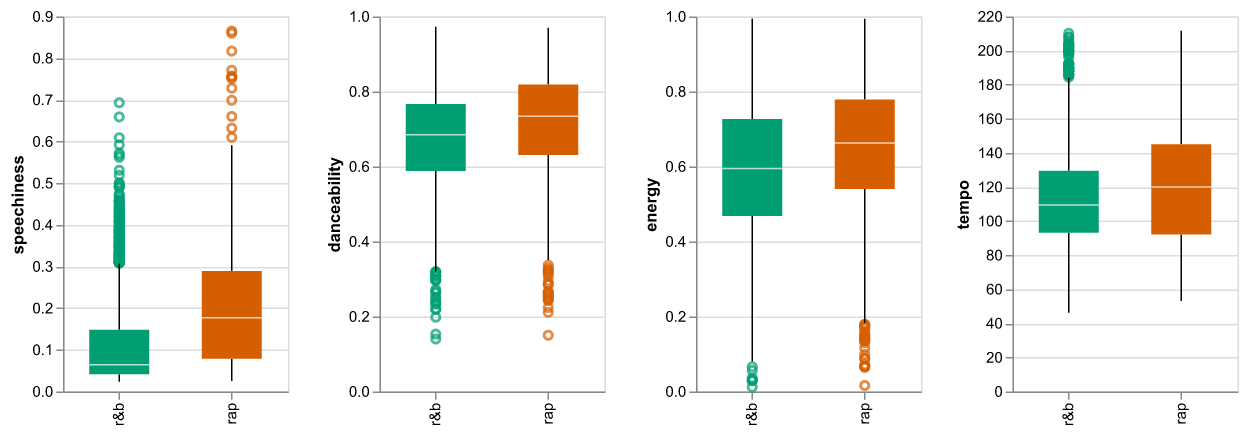

## C · Train and score (8 min · tutorial §3b)

**C1.** Hide one song in four from the model, so you can test it on songs it never saw. `stratify=y` keeps the same
share of each genre in both halves.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X, y = unique[FEATURES], unique['playlist_genre']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)
model = RandomForestClassifier(300, random_state=0)
model.fit(X_tr, y_tr)
guess = model.predict(X_te)

**C2.** How often is it right, and what would the lazy answer score: always the commoner genre?

In [7]:
accuracy = (guess == y_te).mean()
lazy = y_te.value_counts(normalize=True).max()
check(abs(accuracy - 0.781) < 0.01 and abs(lazy - 0.526) < 0.01,
      f'the model: {accuracy:.0%}; the lazy answer: {lazy:.0%}', 'is random_state=0 there, and stratify=y?')

✅ the model: 78%; the lazy answer: 53%


> 👀 **You should see:** ✅ the model: 78%; the lazy answer: 53%. It has learnt something real.

## D · Where is it wrong, and what does it listen to? (14 min · tutorial §4b and §3b)

**D1.** A confusion matrix as shares of each real genre: each row adds up to 100%.

<details><summary>💡 <b>Hint</b></summary>

Divide each row by its own total: `counts.sum(axis=1, keepdims=True)`. Cells are `mark_rect`.
</details>

In [8]:
from sklearn.metrics import confusion_matrix

labels = ['r&b', 'rap']
counts = confusion_matrix(y_te, guess, labels=labels)
share = counts / counts.sum(axis=1, keepdims=True)
cm = (pd.DataFrame(share, index=labels, columns=labels)
        .reset_index(names='true')
        .melt('true', var_name='guessed', value_name='share'))

base = alt.Chart(cm).encode(
    x=alt.X('guessed:N', title='the model guessed'),
    y=alt.Y('true:N', title='the real genre'))
cells = base.mark_rect().encode(
    color=alt.Color('share:Q', scale=alt.Scale(scheme='blues', domain=[0, 1]), legend=None))
words = base.mark_text(fontSize=20).encode(
    text=alt.Text('share:Q', format='.0%'),
    color=alt.when(alt.datum.share > 0.5).then(alt.value('white')).otherwise(alt.value('black')))
(cells + words).properties(width=260, height=260)

alt.LayerChart(...)

> 👀 **You should see:** a 2 × 2 grid. Rap is recognised 84% of the time, R&B 72%: R&B is mistaken for rap more often than the other way round.

> 🖼️ **Plan B: the chart, as a picture**
>
> 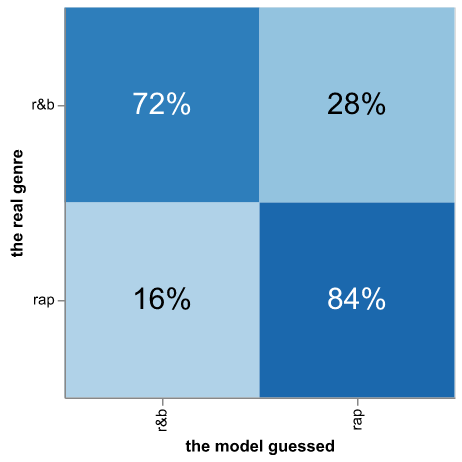

**D2.** Shuffle each column in turn on the test songs: how much accuracy does the model lose?

In [9]:
from sklearn.inspection import permutation_importance

shuffled = permutation_importance(model, X_te, y_te, n_repeats=5, random_state=0)
scores = pd.DataFrame({'feature': FEATURES, 'lost': shuffled.importances_mean})

alt.Chart(scores).mark_bar(color='#0c3354').encode(
    x=alt.X('lost:Q', axis=alt.Axis(format='%'), title='accuracy lost when shuffled'),
    y=alt.Y('feature:N', sort='-x', title=None),
).properties(width=420, height=260)

alt.Chart(...)

> 👀 **You should see:** speechiness far ahead of the rest, then tempo. Compare with your guess in B.

> 🖼️ **Plan B: the chart, as a picture**
>
> 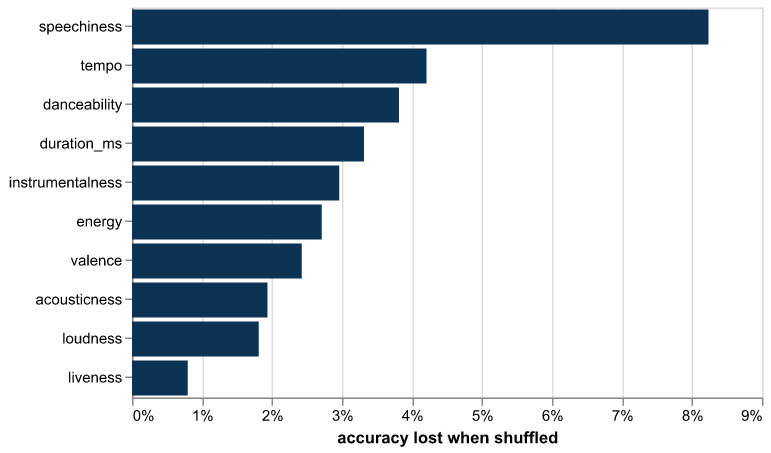

## E · Learning, or memorising? (10 min · tutorial §4c)

**E1.** One tree, allowed to ask more and more questions (`max_depth`). Score it on the songs it learnt from and on
songs it never saw.

In [10]:
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeClassifier

depths = list(range(1, 21))
train, test = validation_curve(
    DecisionTreeClassifier(random_state=0), X, y,
    param_name='max_depth', param_range=depths, cv=3)
curve = pd.DataFrame({'depth': depths,
    'songs it learnt from': train.mean(axis=1),
    'songs it never saw': test.mean(axis=1),
}).melt('depth', var_name='scored on', value_name='accuracy')

alt.Chart(curve).mark_line(point=True).encode(
    x=alt.X('depth:Q', title='how deep the tree may grow'),
    y=alt.Y('accuracy:Q', axis=alt.Axis(format='%'), scale=alt.Scale(zero=False)),
    color=alt.Color('scored on:N', scale=alt.Scale(range=['#9aa3ad', '#c8102e'])),
).properties(width=420, height=260)

alt.Chart(...)

> 👀 **You should see:** grey climbs to 100%; red peaks near depth 9 (71%) and then slips to 68%. Past the peak the tree memorises.

> 🖼️ **Plan B: the chart, as a picture**
>
> 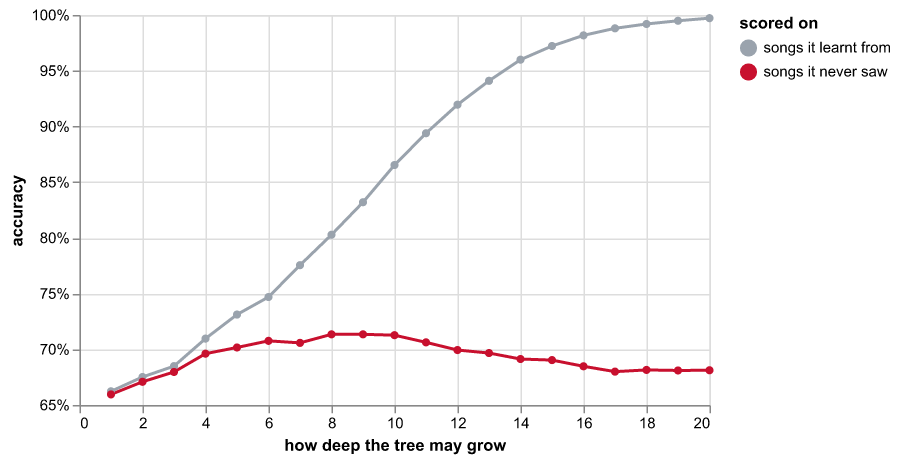

**E2.** Find the best depth in code.

In [11]:
new = curve[curve['scored on'] == 'songs it never saw']
best = new.loc[new['accuracy'].idxmax(), 'depth']
check(best == 9, f'best on new songs at depth {best}', "the row with the highest accuracy: its 'depth'")

✅ best on new songs at depth 9


## F · Tell the public (10 min · tutorial §5) and hand in

**F1.** One honest chart: the model, the lazy answer, and how often each genre is recognised, on one axis from 0 to
100%. Then **write its title as a finding** (Week 9): what should a reader take away?

In [12]:
recall = {g: ((guess == g) & (y_te == g)).sum() / (y_te == g).sum() for g in labels}
honest = pd.DataFrame({'claim': [
        'the model is right', 'always saying "rap" is right',
        'real rap songs it recognises', 'real R&B songs it recognises'],
    'share': [accuracy, lazy, recall['rap'], recall['r&b']]})

finding = 'The audio tells rap from R&B 78% of the time, and misses R&B more often'

bars = alt.Chart(honest).mark_bar(color='#0c3354').encode(
    x=alt.X('share:Q', axis=alt.Axis(format='%'), scale=alt.Scale(domain=[0, 1]), title=None),
    y=alt.Y('claim:N', sort=None, title=None))
labels_on = bars.mark_text(align='left', dx=6).encode(text=alt.Text('share:Q', format='.0%'))
(bars + labels_on).properties(width=420, height=170,
    title=alt.Title(finding, subtitle='Songs the model had never seen; the genre is the playlist’s'))

alt.LayerChart(...)

> 👀 **You should see:** four bars on one 0–100% axis, with the student's finding as the title.

> 🖼️ **Plan B: the chart, as a picture**
>
> 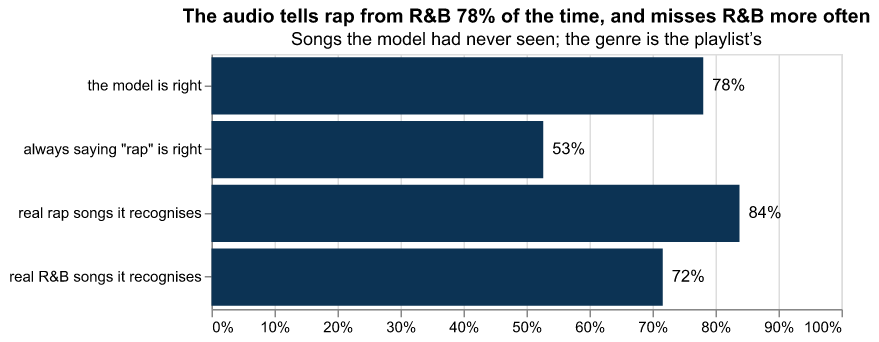

**F2 · Hand in** (Canvas, by midday on the Friday after the lab): this notebook, run top to bottom, and under this
cell **one sentence per part** (A to F) saying what its chart or number shows. For F, add: *what would a reader need
to know to disagree with your title?*

> **Teacher:** **Marking guide (6 marks, one per part).** A: names the 201 double-filed songs as label noise. B: picks
> speechiness, from the boxes. C: reports 78% **against** 53%. D: says R&B is missed more often than rap, and that
> importance is not cause. E: names a depth near 9 and calls the gap memorising. F: a title that is a finding, the
> baseline on the chart, and one thing a reader would need (the labels are the playlist's; only 10,423 songs from 2020
> playlists; a different split moves the score by a point or two).
> 
> **Sample F sentence (excellent):** "The audio alone tells rap from R&B 78% of the time, against 53% for always
> guessing rap; it misses R&B more often, and 201 songs carry both labels, so some of its 'mistakes' are the
> playlists'."